# Early Academic Risk Prediction and Student Support System
## Notebook 02: Exploratory Data Analysis (EDA)

---

### Section 1: Data Loading and Preparation

In this section, we load the required OULAD tables, inspect dataset dimensions, column data types, and check for missing values and duplicate records.

In [1]:
import sys
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')

# Configure visualization styling and display defaults
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 1000)

print("Libraries and visualization defaults successfully loaded.")

Libraries and visualization defaults successfully loaded.


In [2]:
# Dynamically resolve project root and raw dataset directory
current_dir = Path.cwd()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
data_dir = project_root / "data" / "raw" / "oulad"

# Load OULAD tables with '?' treated as missing values and optimized data types
courses = pd.read_csv(data_dir / "courses.csv")
assessments = pd.read_csv(data_dir / "assessments.csv", na_values='?')
vle = pd.read_csv(data_dir / "vle.csv", na_values='?')
student_info = pd.read_csv(data_dir / "studentInfo.csv", na_values='?')
student_registration = pd.read_csv(data_dir / "studentRegistration.csv", na_values='?')
student_assessment = pd.read_csv(data_dir / "studentAssessment.csv", na_values='?')
student_vle = pd.read_csv(
    data_dir / "studentVle.csv",
    dtype={
        'code_module': 'category',
        'code_presentation': 'category',
        'id_student': 'int32',
        'id_site': 'int32',
        'date': 'float32',
        'sum_click': 'int16'
    }
)

print(f"Data loading complete. Successfully loaded 7 tables from: {data_dir.resolve()}")

Data loading complete. Successfully loaded 7 tables from: D:\STD_SUPPORT_project\data\raw\oulad


In [3]:
# Structural and data quality audit across all 7 loaded tables
datasets = {
    "courses": courses,
    "assessments": assessments,
    "vle": vle,
    "student_info": student_info,
    "student_registration": student_registration,
    "student_assessment": student_assessment,
    "student_vle": student_vle
}

audit_records = []
for name, df in datasets.items():
    total_cells = df.shape[0] * df.shape[1]
    missing_count = int(df.isna().sum().sum())
    pct_missing = (missing_count / total_cells * 100) if total_cells > 0 else 0.0
    duplicate_count = int(df.duplicated().sum())
    num_vars = len(df.select_dtypes(include=[np.number]).columns)
    cat_vars = len(df.select_dtypes(include=['object', 'category', 'string']).columns)
    mem_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
    
    audit_records.append({
        "Table Name": name,
        "Rows": f"{df.shape[0]:,}",
        "Columns": df.shape[1],
        "Missing Values": f"{missing_count:,}",
        "Missing (%)": f"{pct_missing:.2f}%",
        "Duplicate Rows": f"{duplicate_count:,}",
        "Numeric Cols": num_vars,
        "Categorical Cols": cat_vars,
        "Memory (MB)": f"{mem_mb:.1f}"
    })

audit_df = pd.DataFrame(audit_records)
print("=== OULAD Dataset Structure & Data Quality Audit ===")
display(audit_df)

=== OULAD Dataset Structure & Data Quality Audit ===


,Table Name,Rows,Columns,Missing Values,Missing (%),Duplicate Rows,Numeric Cols,Categorical Cols,Memory (MB)
0,courses,22,3,0,0.00%,0,1,2,0.0
1,assessments,206,6,11,0.89%,0,3,3,0.0
2,vle,"6,364",6,"10,486",27.46%,0,3,3,1.3
3,student_info,"32,593",12,"1,111",0.28%,0,3,9,18.5
4,student_registration,"32,593",5,"22,566",13.85%,0,3,2,4.5
5,student_assessment,"173,912",5,173,0.02%,0,5,0,6.6
6,student_vle,"10,655,280",6,0,0.00%,"787,170",4,2,162.6


---

### Section 2: Univariate Analysis

In this section, we analyze the individual distributions of key numerical and categorical variables across demographics, course registration, and assessment scores.

=== Descriptive Statistics: Key Numerical Variables ===


,Variable,Count,Missing,Mean,Std,Min,25%,Median,75%,Max,Skewness
0,num_of_prev_attempts,"32,593",0,0.16,0.48,0.0,0.0,0.0,0.0,6.0,3.81
1,studied_credits,"32,593",0,79.76,41.07,30.0,60.0,60.0,120.0,655.0,1.88
2,date_registration,"32,548",45,-69.41,49.26,-322.0,-100.0,-57.0,-29.0,167.0,-1.01
3,assessment_score,"173,739",173,75.80,18.80,0.0,65.0,80.0,90.0,100.0,-1.08


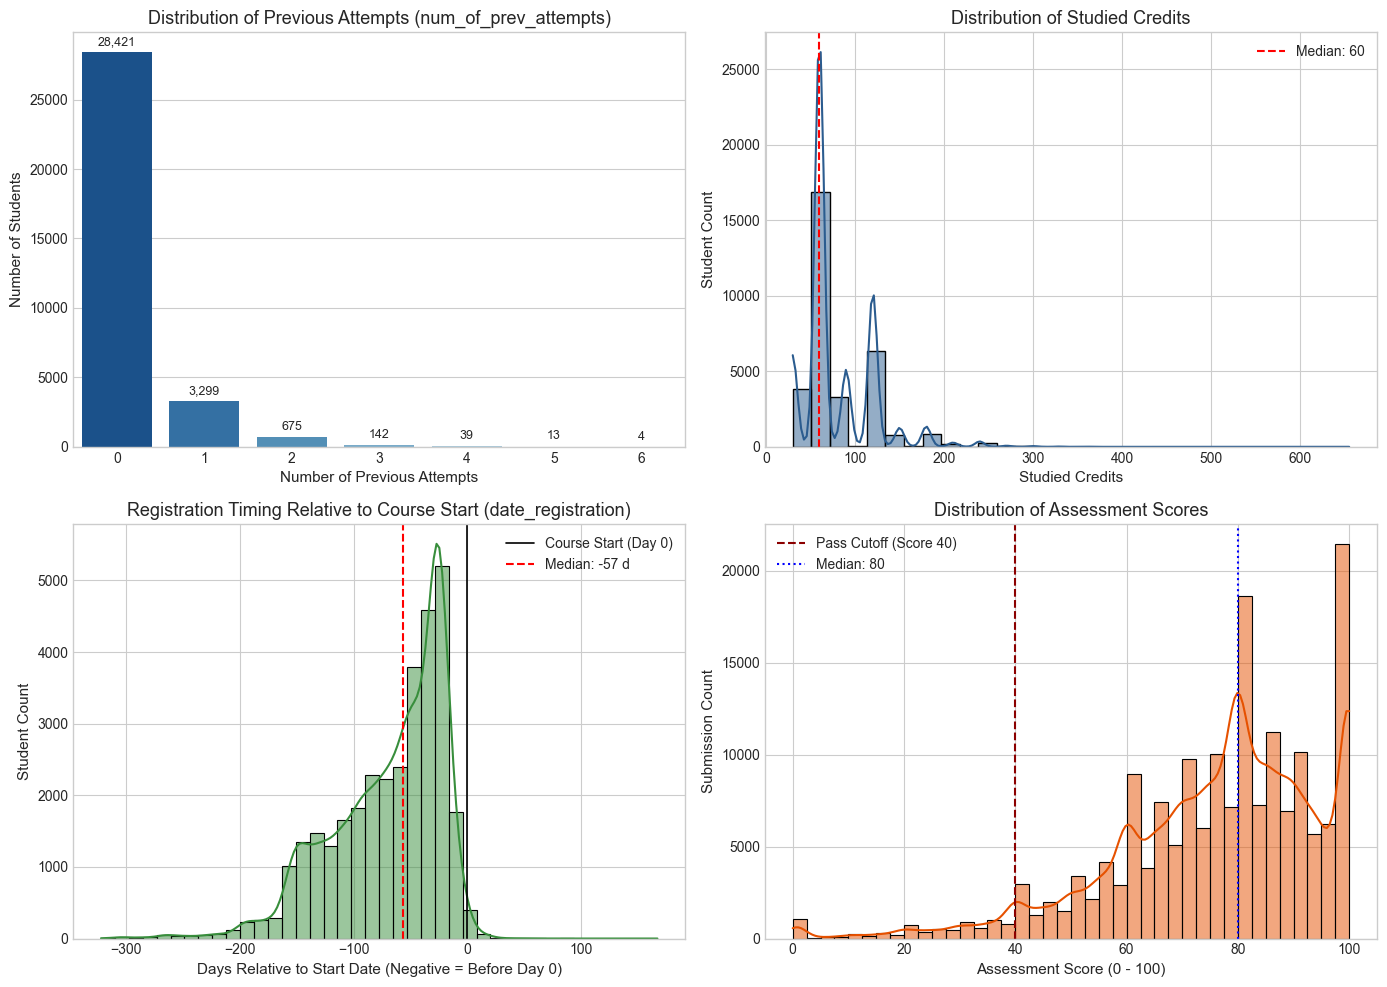

In [4]:
# Descriptive statistics for primary numerical variables
num_cols_summary = {
    'num_of_prev_attempts': student_info['num_of_prev_attempts'],
    'studied_credits': student_info['studied_credits'],
    'date_registration': student_registration['date_registration'],
    'assessment_score': student_assessment['score']
}

num_stats = []
for col_name, s in num_cols_summary.items():
    num_stats.append({
        "Variable": col_name,
        "Count": f"{s.count():,}",
        "Missing": f"{s.isna().sum():,}",
        "Mean": round(s.mean(), 2),
        "Std": round(s.std(), 2),
        "Min": round(s.min(), 2),
        "25%": round(s.quantile(0.25), 2),
        "Median": round(s.median(), 2),
        "75%": round(s.quantile(0.75), 2),
        "Max": round(s.max(), 2),
        "Skewness": round(s.skew(), 2)
    })

num_stats_df = pd.DataFrame(num_stats)
print("=== Descriptive Statistics: Key Numerical Variables ===")
display(num_stats_df)

# Visualizations: 4-panel numerical distributions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Previous attempts
sns.countplot(
    data=student_info,
    x='num_of_prev_attempts',
    ax=axes[0, 0],
    palette='Blues_r'
)
axes[0, 0].set_title('Distribution of Previous Attempts (num_of_prev_attempts)')
axes[0, 0].set_xlabel('Number of Previous Attempts')
axes[0, 0].set_ylabel('Number of Students')
for p in axes[0, 0].patches:
    axes[0, 0].annotate(
        f"{int(p.get_height()):,}",
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points'
    )

# 2. Studied credits
sns.histplot(
    student_info['studied_credits'],
    bins=30,
    kde=True,
    ax=axes[0, 1],
    color='#2b5c8f'
)
axes[0, 1].set_title('Distribution of Studied Credits')
axes[0, 1].set_xlabel('Studied Credits')
axes[0, 1].set_ylabel('Student Count')
axes[0, 1].axvline(
    student_info['studied_credits'].median(),
    color='red', linestyle='--', label=f"Median: {student_info['studied_credits'].median():.0f}"
)
axes[0, 1].legend()

# 3. Registration date
sns.histplot(
    student_registration['date_registration'].dropna(),
    bins=40,
    kde=True,
    ax=axes[1, 0],
    color='#388e3c'
)
axes[1, 0].set_title('Registration Timing Relative to Course Start (date_registration)')
axes[1, 0].set_xlabel('Days Relative to Start Date (Negative = Before Day 0)')
axes[1, 0].set_ylabel('Student Count')
axes[1, 0].axvline(0, color='black', linestyle='-', linewidth=1.2, label='Course Start (Day 0)')
axes[1, 0].axvline(
    student_registration['date_registration'].median(),
    color='red', linestyle='--', label=f"Median: {student_registration['date_registration'].median():.0f} d"
)
axes[1, 0].legend()

# 4. Assessment scores
sns.histplot(
    student_assessment['score'].dropna(),
    bins=40,
    kde=True,
    ax=axes[1, 1],
    color='#e65100'
)
axes[1, 1].set_title('Distribution of Assessment Scores')
axes[1, 1].set_xlabel('Assessment Score (0 - 100)')
axes[1, 1].set_ylabel('Submission Count')
axes[1, 1].axvline(40, color='darkred', linestyle='--', linewidth=1.5, label='Pass Cutoff (Score 40)')
axes[1, 1].axvline(
    student_assessment['score'].median(),
    color='blue', linestyle=':', label=f"Median: {student_assessment['score'].median():.0f}"
)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

=== Categorical Features Distribution Summary (Top Categories) ===


,Feature,Category,Count,Proportion (%)
0,gender,M,"17,875",54.84%
1,gender,F,"14,718",45.16%
2,age_band,0-35,"22,944",70.40%
3,age_band,35-55,"9,433",28.94%
4,age_band,55<=,216,0.66%
5,highest_education,A Level or Equivalent,"14,045",43.09%
6,highest_education,Lower Than A Level,"13,158",40.37%
7,highest_education,HE Qualification,"4,730",14.51%
8,highest_education,No Formal quals,347,1.06%
9,highest_education,Post Graduate Qualification,313,0.96%


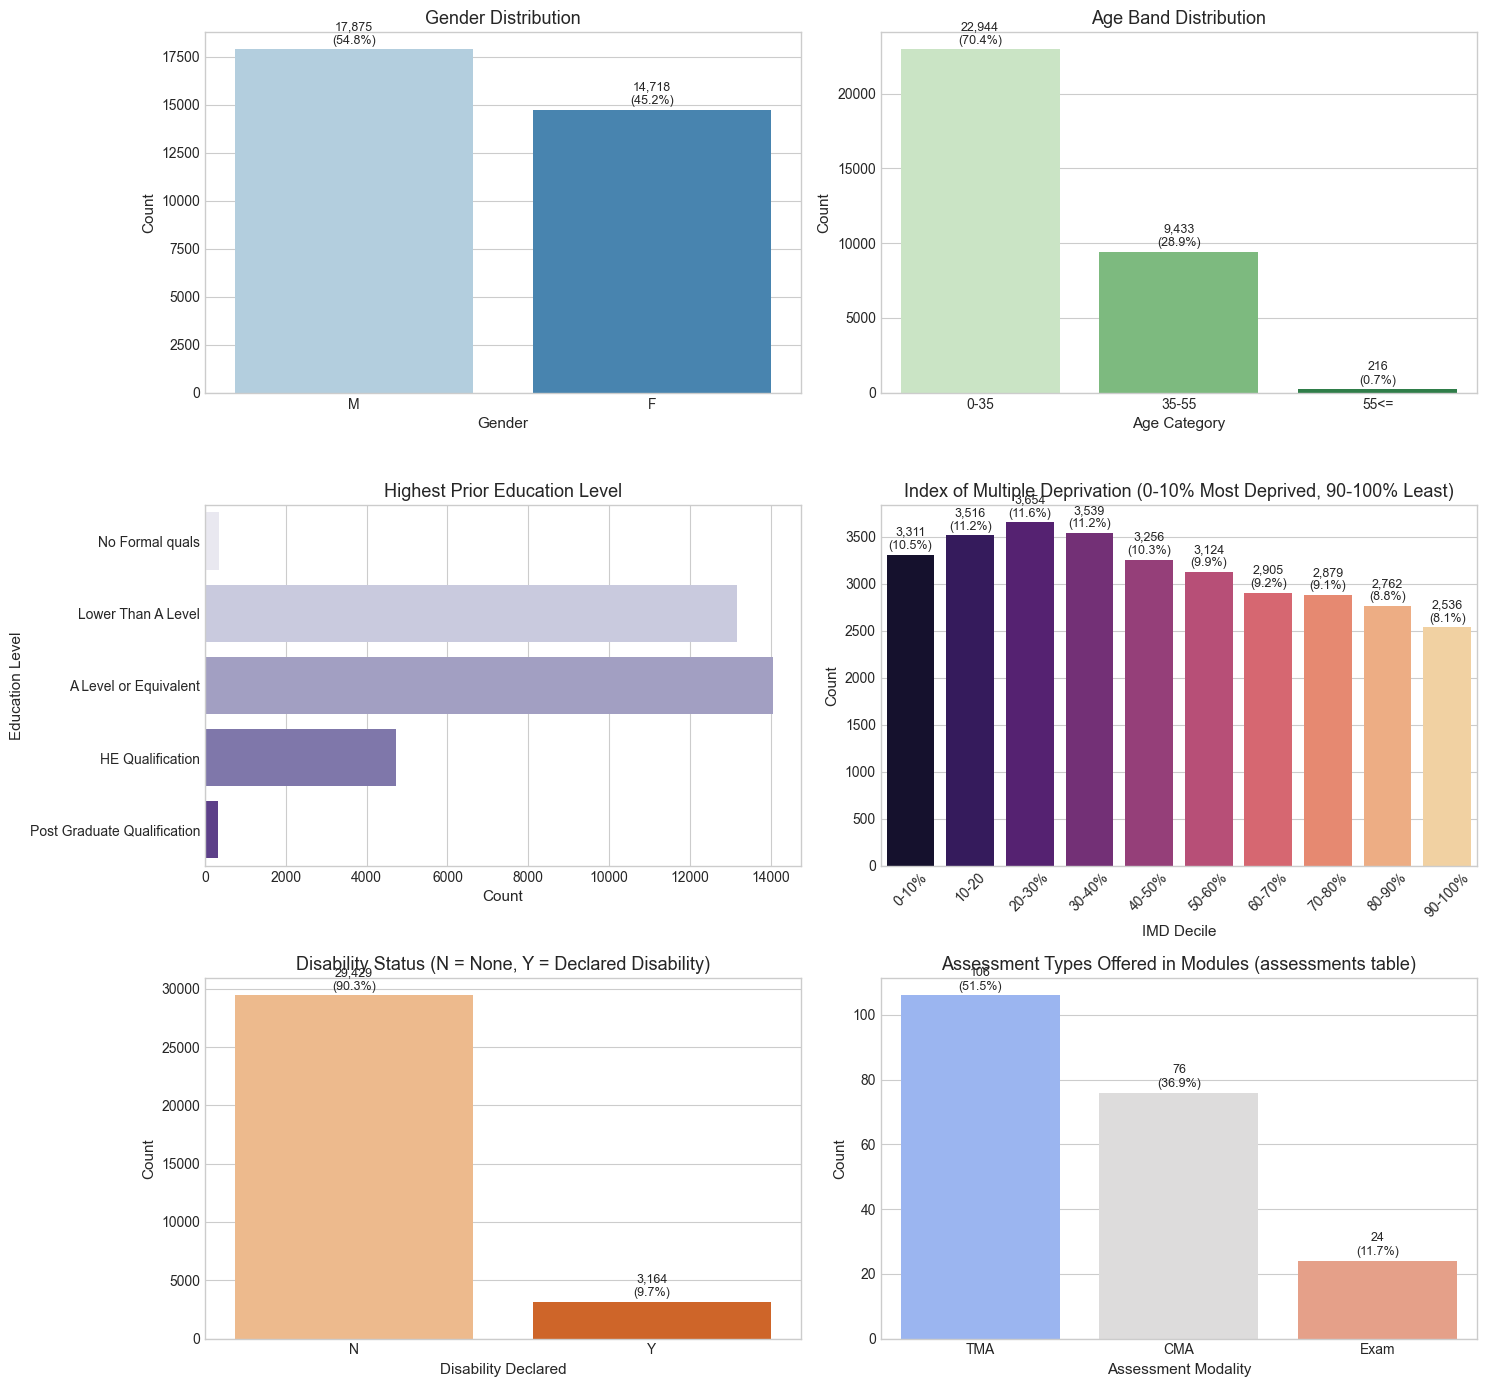

In [5]:
# Categorical distributions and proportion summary
cat_features = ['gender', 'age_band', 'highest_education', 'imd_band', 'disability']

cat_summary_rows = []
for col in cat_features:
    counts = student_info[col].value_counts(dropna=False)
    pcts = student_info[col].value_counts(normalize=True, dropna=False) * 100
    for cat, count in counts.items():
        cat_summary_rows.append({
            "Feature": col,
            "Category": str(cat),
            "Count": f"{count:,}",
            "Proportion (%)": f"{pcts[cat]:.2f}%"
        })

cat_summary_df = pd.DataFrame(cat_summary_rows)
print("=== Categorical Features Distribution Summary (Top Categories) ===")
display(cat_summary_df.head(15))

# Visualizations: 6-panel categorical count plots
fig, axes = plt.subplots(3, 2, figsize=(15, 14))

# 1. Gender
sns.countplot(data=student_info, x='gender', ax=axes[0, 0], palette='Blues', order=['M', 'F'])
axes[0, 0].set_title('Gender Distribution')
axes[0, 0].set_xlabel('Gender')
axes[0, 0].set_ylabel('Count')

# 2. Age band
age_order = ['0-35', '35-55', '55<=']
sns.countplot(data=student_info, x='age_band', ax=axes[0, 1], palette='Greens', order=age_order)
axes[0, 1].set_title('Age Band Distribution')
axes[0, 1].set_xlabel('Age Category')
axes[0, 1].set_ylabel('Count')

# 3. Highest education
edu_order = [
    'No Formal quals',
    'Lower Than A Level',
    'A Level or Equivalent',
    'HE Qualification',
    'Post Graduate Qualification'
]
sns.countplot(data=student_info, y='highest_education', ax=axes[1, 0], palette='Purples', order=edu_order)
axes[1, 0].set_title('Highest Prior Education Level')
axes[1, 0].set_xlabel('Count')
axes[1, 0].set_ylabel('Education Level')

# 4. IMD band (Deprivation decile)
imd_order = [
    '0-10%', '10-20', '20-30%', '30-40%', '40-50%',
    '50-60%', '60-70%', '70-80%', '80-90%', '90-100%'
]
sns.countplot(
    data=student_info.dropna(subset=['imd_band']),
    x='imd_band',
    ax=axes[1, 1],
    palette='magma',
    order=imd_order
)
axes[1, 1].set_title('Index of Multiple Deprivation (0-10% Most Deprived, 90-100% Least)')
axes[1, 1].set_xlabel('IMD Decile')
axes[1, 1].set_ylabel('Count')
axes[1, 1].tick_params(axis='x', rotation=45)

# 5. Disability status
sns.countplot(data=student_info, x='disability', ax=axes[2, 0], palette='Oranges', order=['N', 'Y'])
axes[2, 0].set_title('Disability Status (N = None, Y = Declared Disability)')
axes[2, 0].set_xlabel('Disability Declared')
axes[2, 0].set_ylabel('Count')

# 6. Assessment types in curriculum
sns.countplot(data=assessments, x='assessment_type', ax=axes[2, 1], palette='coolwarm', order=['TMA', 'CMA', 'Exam'])
axes[2, 1].set_title('Assessment Types Offered in Modules (assessments table)')
axes[2, 1].set_xlabel('Assessment Modality')
axes[2, 1].set_ylabel('Count')

# Add percentage annotations to bars
for ax in [axes[0, 0], axes[0, 1], axes[1, 1], axes[2, 0], axes[2, 1]]:
    denom = len(student_info) if ax != axes[2, 1] else len(assessments)
    if ax == axes[1, 1]:
        denom = len(student_info.dropna(subset=['imd_band']))
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            pct = (h / denom) * 100
            ax.annotate(
                f"{int(h):,}\n({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2., h),
                ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points'
            )

plt.tight_layout()
plt.show()

---

### Section 3: Target Variable Analysis (`final_result`)

In this section, we investigate the target variable `final_result`, evaluate class distribution and imbalance across all four outcomes, and analyze its relationship to academic risk.

=== Target Variable Distribution (final_result) ===

=== Binary Risk Framing (Intervention Target) ===


,Outcome Category,Student Count,Proportion (%),Academic Classification
0,Pass,12361,37.93,Successful Completion
1,Withdrawn,10156,31.16,Early Departure (At-Risk)
2,Fail,7052,21.64,Academic Failure (At-Risk)
3,Distinction,3024,9.28,High Academic Success


,Risk Classification,Student Count,Proportion (%)
0,At-Risk (Fail / Withdrawn),17208,52.8
1,Success (Pass / Distinction),15385,47.2


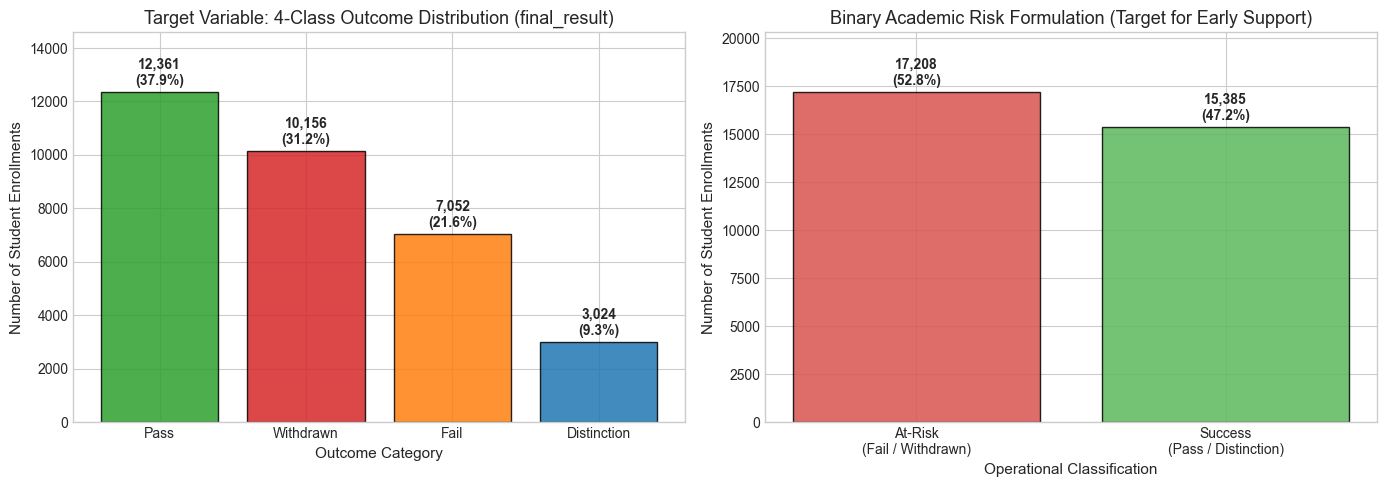

In [6]:
# Target variable distribution and percentage calculation
target_counts = student_info['final_result'].value_counts()
target_pcts = (student_info['final_result'].value_counts(normalize=True) * 100).round(2)
total_enrollments = len(student_info)

target_summary = pd.DataFrame({
    "Outcome Category": target_counts.index,
    "Student Count": target_counts.values,
    "Proportion (%)": target_pcts.values,
    "Academic Classification": [
        "Successful Completion",
        "Early Departure (At-Risk)",
        "Academic Failure (At-Risk)",
        "High Academic Success"
    ]
})

print("=== Target Variable Distribution (final_result) ===")
display(target_summary)

# Binary risk classification (Operational Support Framing)
at_risk_count = int(student_info['final_result'].isin(['Fail', 'Withdrawn']).sum())
successful_count = int(student_info['final_result'].isin(['Pass', 'Distinction']).sum())

binary_summary = pd.DataFrame({
    "Risk Classification": [
        "At-Risk (Fail / Withdrawn)",
        "Success (Pass / Distinction)"
    ],
    "Student Count": [at_risk_count, successful_count],
    "Proportion (%)": [
        round(at_risk_count / total_enrollments * 100, 2),
        round(successful_count / total_enrollments * 100, 2)
    ]
})
print("\n=== Binary Risk Framing (Intervention Target) ===")
display(binary_summary)

# Visualizations: Dual bar chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. 4-Class Outcome Distribution
colors_4 = ['#2ca02c', '#d62728', '#ff7f0e', '#1f77b4']
bars1 = ax1.bar(target_counts.index, target_counts.values, color=colors_4, edgecolor='black', alpha=0.85)
ax1.set_title('Target Variable: 4-Class Outcome Distribution (final_result)')
ax1.set_xlabel('Outcome Category')
ax1.set_ylabel('Number of Student Enrollments')
for bar in bars1:
    yval = bar.get_height()
    pct = (yval / total_enrollments) * 100
    ax1.text(
        bar.get_x() + bar.get_width() / 2., yval + 150,
        f"{int(yval):,}\n({pct:.1f}%)",
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )
ax1.set_ylim(0, max(target_counts.values) * 1.18)

# 2. 2-Class Binary Risk Distribution
risk_labels = ['At-Risk\n(Fail / Withdrawn)', 'Success\n(Pass / Distinction)']
risk_vals = [at_risk_count, successful_count]
colors_2 = ['#d9534f', '#5cb85c']
bars2 = ax2.bar(risk_labels, risk_vals, color=colors_2, edgecolor='black', alpha=0.85)
ax2.set_title('Binary Academic Risk Formulation (Target for Early Support)')
ax2.set_xlabel('Operational Classification')
ax2.set_ylabel('Number of Student Enrollments')
for bar in bars2:
    yval = bar.get_height()
    pct = (yval / total_enrollments) * 100
    ax2.text(
        bar.get_x() + bar.get_width() / 2., yval + 200,
        f"{int(yval):,}\n({pct:.1f}%)",
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )
ax2.set_ylim(0, max(risk_vals) * 1.18)

plt.tight_layout()
plt.show()

---

### Section 4: Bivariate Analysis

In this section, we explore relationships between student demographic variables, prior academic history, registration timing, and the target variable `final_result`.

=== Detailed Cross-Tabulation: num_of_prev_attempts vs final_result (%) ===

=== Detailed Cross-Tabulation: highest_education vs final_result (%) ===


final_result,Distinction,Pass,Fail,Withdrawn
num_of_prev_attempts,,,,
0,10.05,39.22,20.16,30.56
1,4.33,30.22,30.59,34.86
2,3.26,25.19,34.96,36.59
3,0.70,21.83,40.14,37.32
4,0.00,33.33,30.77,35.90
5,0.00,15.38,46.15,38.46
6,25.00,0.00,25.00,50.00


final_result,Distinction,Pass,Fail,Withdrawn
highest_education,,,,
A Level or Equivalent,10.65,41.38,19.27,28.69
HE Qualification,14.74,41.44,16.70,27.12
Lower Than A Level,5.53,33.33,26.04,35.11
No Formal quals,4.61,25.07,27.38,42.94
Post Graduate Qualification,28.12,37.38,10.86,23.64


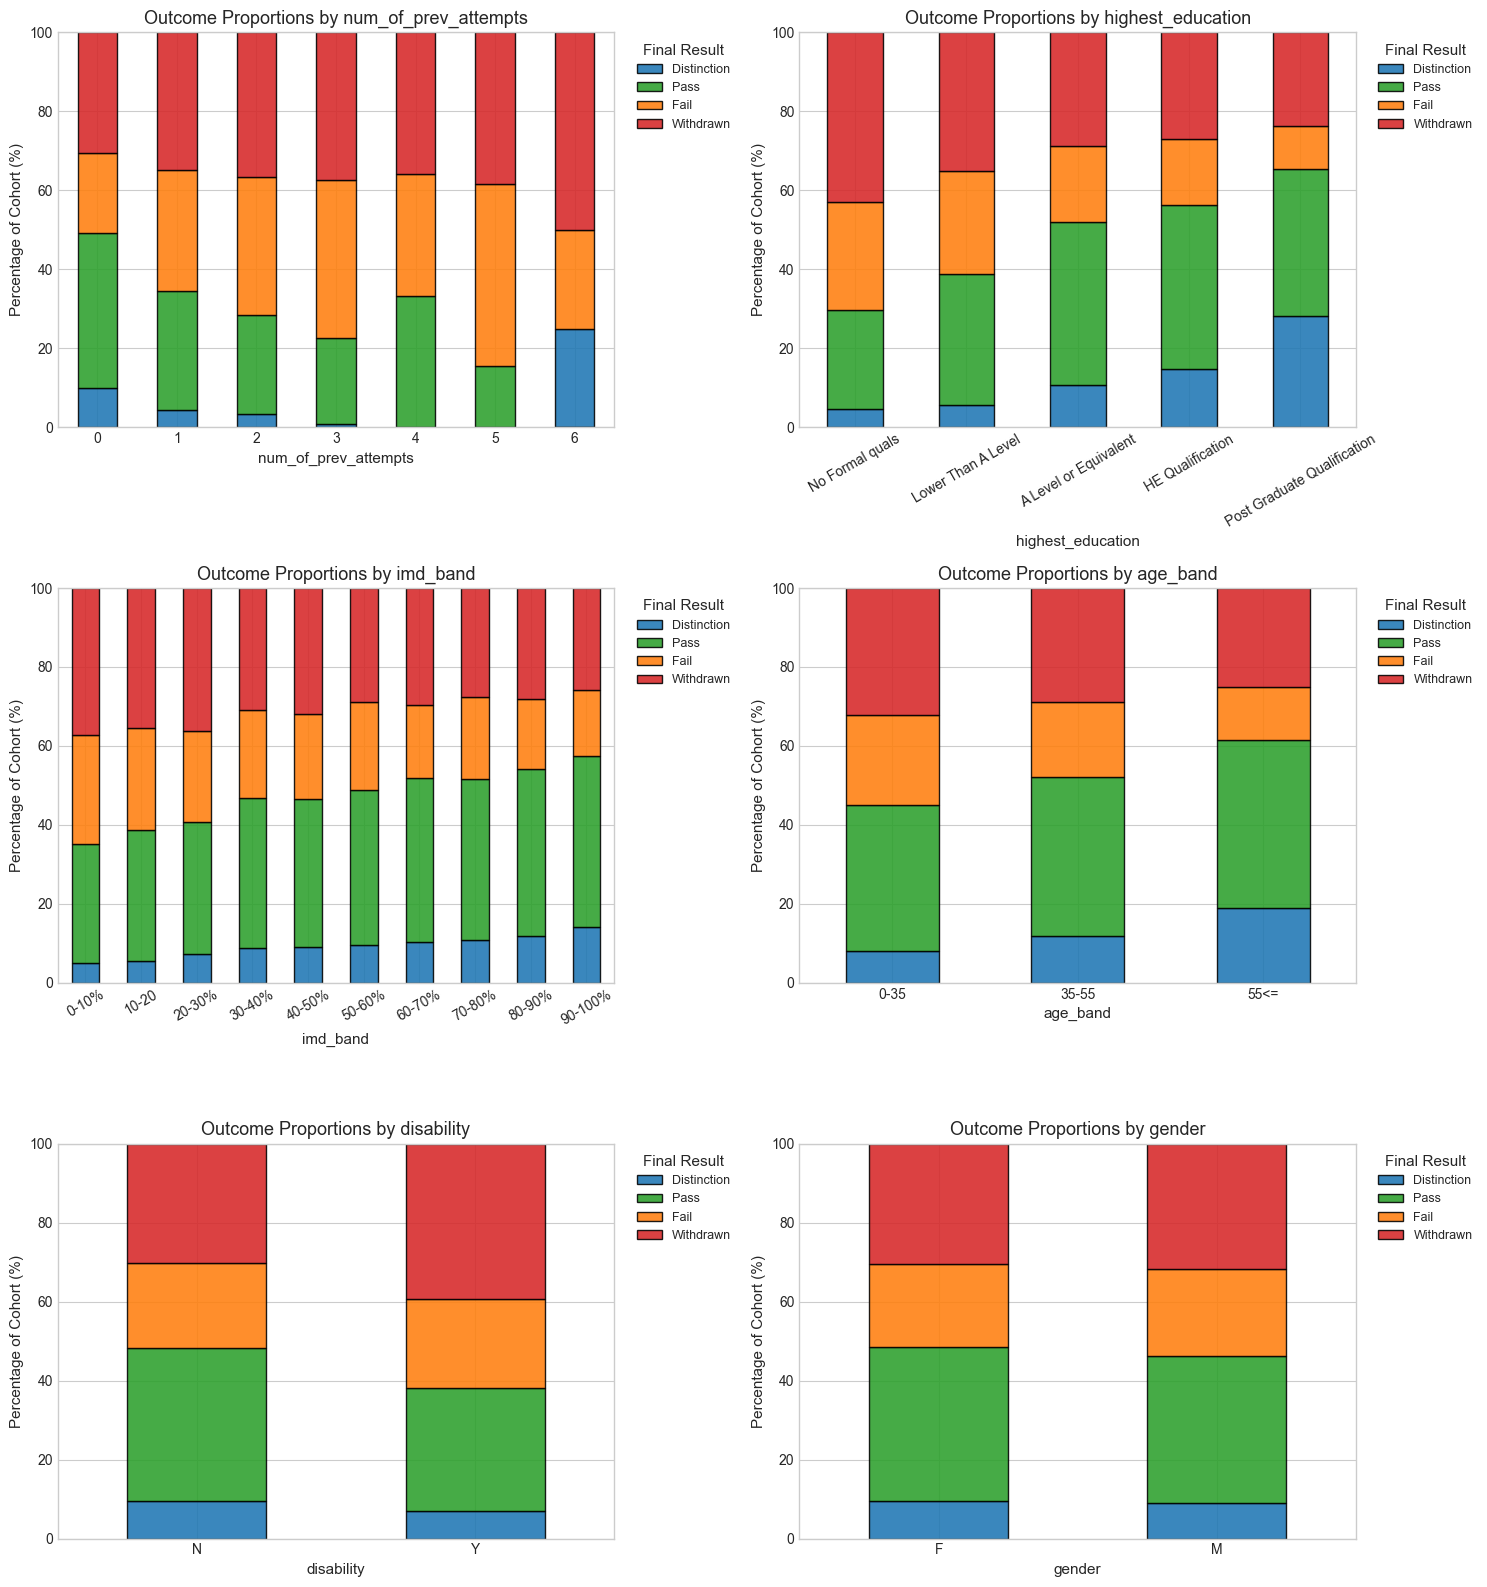

In [7]:
# Demographic and categorical features vs final_result
bivariate_features = [
    'num_of_prev_attempts',
    'highest_education',
    'imd_band',
    'age_band',
    'disability',
    'gender'
]
result_order = ['Distinction', 'Pass', 'Fail', 'Withdrawn']
palette_outcomes = {
    'Distinction': '#1f77b4',
    'Pass': '#2ca02c',
    'Fail': '#ff7f0e',
    'Withdrawn': '#d62728'
}

fig, axes = plt.subplots(3, 2, figsize=(15, 16))
axes_flat = axes.flatten()

for idx, col in enumerate(bivariate_features):
    ax = axes_flat[idx]
    ct = pd.crosstab(student_info[col], student_info['final_result'], normalize='index')[result_order] * 100
    
    if col == 'highest_education':
        edu_order_exist = [e for e in edu_order if e in ct.index]
        ct = ct.reindex(edu_order_exist)
    elif col == 'imd_band':
        imd_order_exist = [m for m in imd_order if m in ct.index]
        ct = ct.reindex(imd_order_exist)
    elif col == 'age_band':
        ct = ct.reindex(['0-35', '35-55', '55<='])
        
    ct.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=[palette_outcomes[c] for c in result_order],
        edgecolor='black',
        alpha=0.88
    )
    ax.set_title(f'Outcome Proportions by {col}')
    ax.set_ylabel('Percentage of Cohort (%)')
    ax.set_xlabel(col)
    ax.set_ylim(0, 100)
    ax.legend(title='Final Result', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
    ax.tick_params(axis='x', rotation=30 if col in ['highest_education', 'imd_band'] else 0)

plt.tight_layout()
plt.show()

print("=== Detailed Cross-Tabulation: num_of_prev_attempts vs final_result (%) ===")
display((pd.crosstab(student_info['num_of_prev_attempts'], student_info['final_result'], normalize='index')[result_order] * 100).round(2))

print("\n=== Detailed Cross-Tabulation: highest_education vs final_result (%) ===")
display((pd.crosstab(student_info['highest_education'], student_info['final_result'], normalize='index')[result_order] * 100).round(2))

=== Studied Credits Summary by Final Result ===

=== Registration Timing (date_registration) by Final Result ===


,count,mean,std,25%,50%,75%
final_result,,,,,,
Distinction,3024.0,71.759259,34.690593,60.0,60.0,90.0
Fail,7052.0,76.086926,38.846551,60.0,60.0,90.0
Pass,12361.0,74.220937,36.071382,60.0,60.0,90.0
Withdrawn,10156.0,91.430189,47.141690,60.0,60.0,120.0


,count,mean,std,25%,50%,75%
final_result,,,,,,
Distinction,3024.0,-65.641534,47.004632,-93.0,-52.0,-29.0
Fail,7047.0,-62.814957,45.736098,-92.0,-50.0,-27.0
Pass,12360.0,-66.707848,47.374266,-95.0,-53.0,-29.0
Withdrawn,10117.0,-78.435603,53.133550,-115.0,-67.0,-32.0


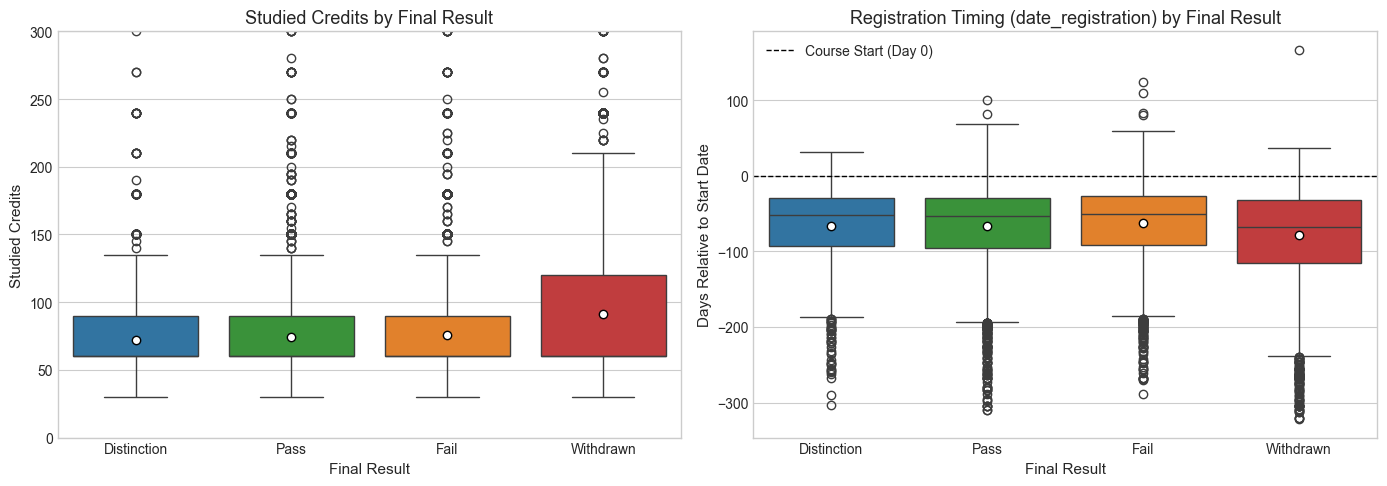

In [8]:
# Merge student_info with registration for continuous bivariate analysis
df_demo_reg = student_info.merge(
    student_registration[['code_module', 'code_presentation', 'id_student', 'date_registration']],
    on=['code_module', 'code_presentation', 'id_student'],
    how='left'
)

# Descriptive stats grouped by final_result
print("=== Studied Credits Summary by Final Result ===")
credits_summary = df_demo_reg.groupby('final_result')['studied_credits'].describe()[['count', 'mean', 'std', '25%', '50%', '75%']]
display(credits_summary)

print("\n=== Registration Timing (date_registration) by Final Result ===")
reg_summary = df_demo_reg.groupby('final_result')['date_registration'].describe()[['count', 'mean', 'std', '25%', '50%', '75%']]
display(reg_summary)

# Visual comparisons: Boxplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Studied credits
sns.boxplot(
    data=df_demo_reg,
    x='final_result',
    y='studied_credits',
    order=result_order,
    palette=palette_outcomes,
    ax=ax1,
    showmeans=True,
    meanprops={'marker': 'o', 'markerfacecolor': 'white', 'markeredgecolor': 'black'}
)
ax1.set_title('Studied Credits by Final Result')
ax1.set_xlabel('Final Result')
ax1.set_ylabel('Studied Credits')
ax1.set_ylim(0, 300)

# 2. Registration timing
sns.boxplot(
    data=df_demo_reg,
    x='final_result',
    y='date_registration',
    order=result_order,
    palette=palette_outcomes,
    ax=ax2,
    showmeans=True,
    meanprops={'marker': 'o', 'markerfacecolor': 'white', 'markeredgecolor': 'black'}
)
ax2.set_title('Registration Timing (date_registration) by Final Result')
ax2.set_xlabel('Final Result')
ax2.set_ylabel('Days Relative to Start Date')
ax2.axhline(0, color='black', linestyle='--', linewidth=1, label='Course Start (Day 0)')
ax2.legend()

plt.tight_layout()
plt.show()

---

### Section 5: Assessment Analysis

In this section, we examine assessment types, score distributions across assessment modalities, submission timeliness, and the relationship between early assessment performance and final student outcomes.

=== Score Statistics by Assessment Modality ===

=== Submission Delay Statistics by Assessment Type (Days Relative to Due Date) ===

=== Late Submission Rates (%) by Assessment Type ===


,count,mean,std,min,25%,50%,75%,max
assessment_type,,,,,,,,
CMA,70527.0,81.027053,17.836026,0.0,72.0,82.0,98.0,100.0
Exam,4959.0,65.572898,20.579186,0.0,51.0,67.0,82.0,100.0
TMA,98253.0,72.563392,18.432823,0.0,63.0,76.0,86.0,100.0


,count,mean,std,min,25%,50%,75%,max
assessment_type,,,,,,,,
CMA,70527.0,-38.335035,64.395772,-246.0,-59.0,-1.0,2.0,372.0
Exam,2094.0,-14.275072,7.110135,-25.0,-20.0,-11.0,-7.0,10.0
TMA,98426.0,-1.176031,10.937337,-216.0,-2.0,-1.0,0.0,198.0


,is_late
assessment_type,
CMA,46.78
Exam,0.14
TMA,16.58


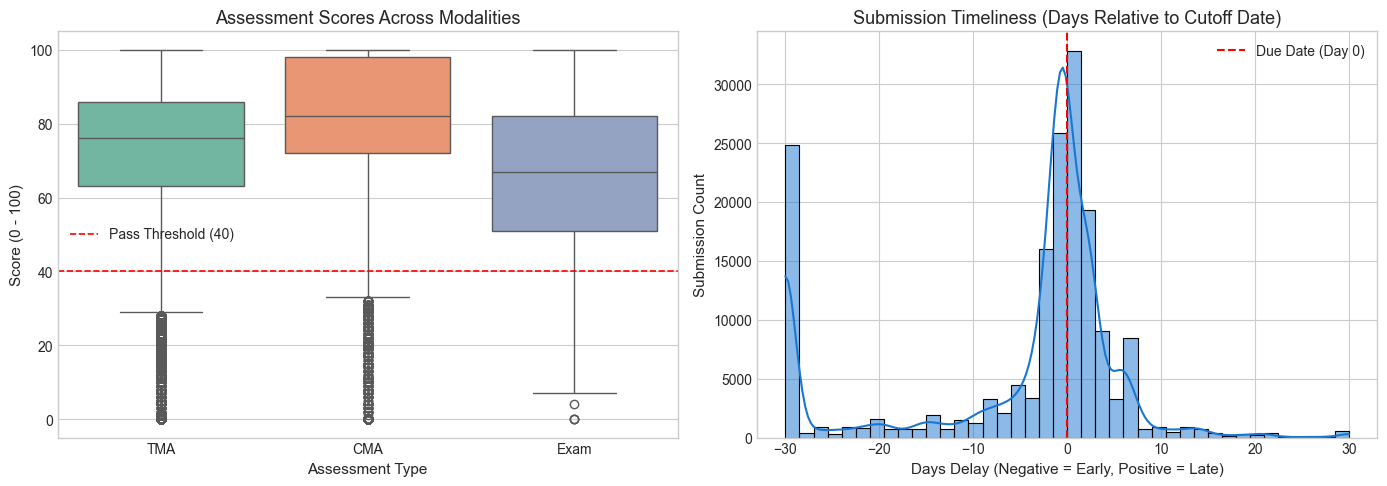

In [9]:
# Merge student assessments with assessment definitions
sa_asm = student_assessment.merge(assessments, on='id_assessment', how='left')

# Descriptive stats by assessment type
print("=== Score Statistics by Assessment Modality ===")
score_type_stats = sa_asm.groupby('assessment_type')['score'].describe()
display(score_type_stats)

# Timeliness analysis: submission_delay = date_submitted - date (due date)
sa_asm['submission_delay'] = sa_asm['date_submitted'] - sa_asm['date']
sa_asm['is_late'] = (sa_asm['submission_delay'] > 0).astype(int)

print("\n=== Submission Delay Statistics by Assessment Type (Days Relative to Due Date) ===")
delay_stats = sa_asm.groupby('assessment_type')['submission_delay'].describe()
display(delay_stats)

late_rates = sa_asm.groupby('assessment_type')['is_late'].mean() * 100
print("\n=== Late Submission Rates (%) by Assessment Type ===")
display(late_rates.round(2))

# Visualizations: Scores and delays
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Score distribution by assessment type
sns.boxplot(
    data=sa_asm,
    x='assessment_type',
    y='score',
    palette='Set2',
    ax=ax1,
    order=['TMA', 'CMA', 'Exam']
)
ax1.set_title('Assessment Scores Across Modalities')
ax1.set_xlabel('Assessment Type')
ax1.set_ylabel('Score (0 - 100)')
ax1.axhline(40, color='red', linestyle='--', linewidth=1.2, label='Pass Threshold (40)')
ax1.legend()

# Submission delay distribution (clipped between -30 and 30 for visualization clarity)
delay_clipped = sa_asm['submission_delay'].clip(-30, 30)
sns.histplot(
    delay_clipped,
    bins=40,
    kde=True,
    ax=ax2,
    color='#1976d2'
)
ax2.set_title('Submission Timeliness (Days Relative to Cutoff Date)')
ax2.set_xlabel('Days Delay (Negative = Early, Positive = Late)')
ax2.set_ylabel('Submission Count')
ax2.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Due Date (Day 0)')
ax2.legend()

plt.tight_layout()
plt.show()

=== Non-Submission Rate Across Final Results (%) ===

=== Mean Assessment Score Across Final Results ===

=== Early Assessment Mean Score (Due <= Day 60) Across Final Results ===


,Zero Assessment Submissions (%)
final_result,
Distinction,0.00
Fail,18.21
Pass,0.02
Withdrawn,53.79


,count,mean,std,min,25%,50%,75%,max
final_result,,,,,,,,
Distinction,3024.0,88.493066,6.647903,48.428571,85.750000,89.416667,92.777778,100.0
Fail,5765.0,64.230604,16.817770,0.000000,54.800000,65.916667,76.090909,100.0
Pass,12358.0,76.178802,10.491878,27.000000,70.083333,77.857143,83.888889,98.5
Withdrawn,4673.0,64.105760,21.385183,0.000000,52.200000,68.000000,80.000000,100.0


,count,mean,std,min,25%,50%,75%,max
final_result,,,,,,,,
Distinction,2628.0,88.528792,10.490670,28.0,85.333333,90.0,95.0,100.0
Fail,5238.0,67.699949,17.951155,0.0,58.000000,70.0,80.0,100.0
Pass,11221.0,78.181015,13.422191,0.0,72.500000,80.5,87.0,100.0
Withdrawn,4531.0,65.102810,21.949500,0.0,54.000000,69.0,81.0,100.0


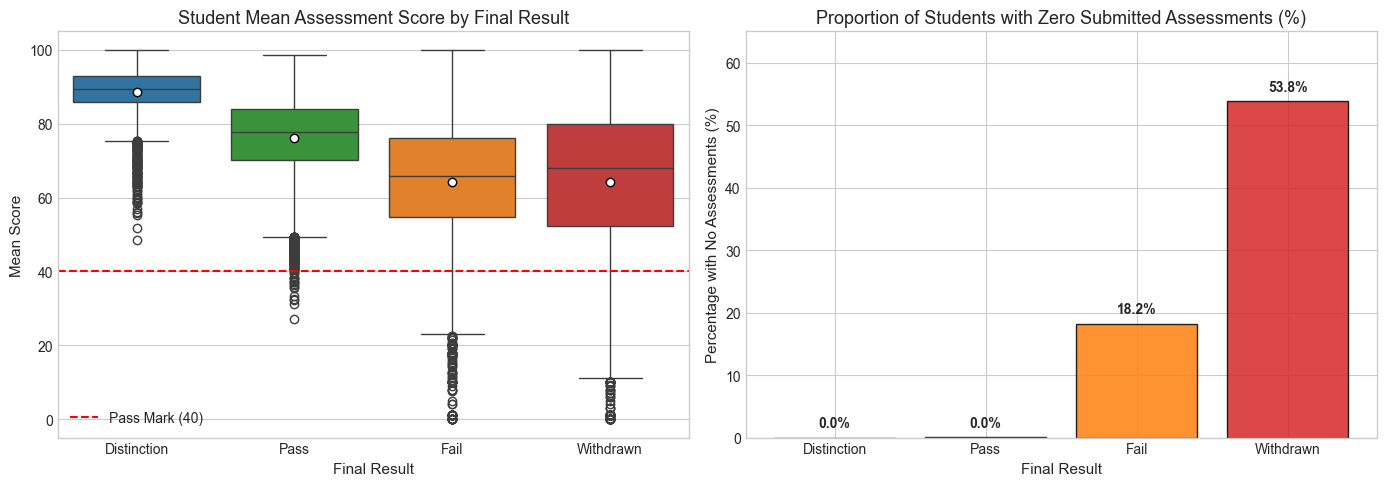

In [10]:
# Student-level assessment aggregations by module presentation enrollment
asmt_student = sa_asm.groupby(['code_module', 'code_presentation', 'id_student']).agg(
    assessments_submitted=('score', 'count'),
    mean_assessment_score=('score', 'mean'),
    late_submissions=('is_late', 'sum')
).reset_index()

# Early assessments: due date on or before Day 60
sa_early = sa_asm[sa_asm['date'] <= 60]
asmt_early = sa_early.groupby(['code_module', 'code_presentation', 'id_student']).agg(
    early_assessments_submitted=('score', 'count'),
    early_mean_score=('score', 'mean')
).reset_index()

# Merge with student_info
df_asmt_perf = student_info.merge(asmt_student, on=['code_module', 'code_presentation', 'id_student'], how='left')
df_asmt_perf = df_asmt_perf.merge(asmt_early, on=['code_module', 'code_presentation', 'id_student'], how='left')

# Non-submission indicator
df_asmt_perf['no_assessment_submitted'] = df_asmt_perf['assessments_submitted'].isna()

print("=== Non-Submission Rate Across Final Results (%) ===")
non_sub_rate = pd.crosstab(df_asmt_perf['final_result'], df_asmt_perf['no_assessment_submitted'], normalize='index')[True] * 100
display(non_sub_rate.round(2).rename('Zero Assessment Submissions (%)'))

print("\n=== Mean Assessment Score Across Final Results ===")
score_by_result = df_asmt_perf.groupby('final_result')['mean_assessment_score'].describe()
display(score_by_result)

print("\n=== Early Assessment Mean Score (Due <= Day 60) Across Final Results ===")
early_score_by_result = df_asmt_perf.groupby('final_result')['early_mean_score'].describe()
display(early_score_by_result)

# Visualizations: Score and non-submission rate
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Mean assessment score by final result
sns.boxplot(
    data=df_asmt_perf,
    x='final_result',
    y='mean_assessment_score',
    order=result_order,
    palette=palette_outcomes,
    ax=ax1,
    showmeans=True,
    meanprops={'marker': 'o', 'markerfacecolor': 'white', 'markeredgecolor': 'black'}
)
ax1.set_title('Student Mean Assessment Score by Final Result')
ax1.set_xlabel('Final Result')
ax1.set_ylabel('Mean Score')
ax1.axhline(40, color='red', linestyle='--', label='Pass Mark (40)')
ax1.legend()

# Non-submission percentage bar chart
non_sub_df = non_sub_rate.reindex(result_order)
bars = ax2.bar(
    non_sub_df.index,
    non_sub_df.values,
    color=[palette_outcomes[c] for c in result_order],
    edgecolor='black',
    alpha=0.85
)
ax2.set_title('Proportion of Students with Zero Submitted Assessments (%)')
ax2.set_xlabel('Final Result')
ax2.set_ylabel('Percentage with No Assessments (%)')
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2., yval + 1.2, f"{yval:.1f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')
ax2.set_ylim(0, 65)

plt.tight_layout()
plt.show()

---

### Section 6: Student Engagement Analysis (VLE)

In this section, we analyze student interactions within the Virtual Learning Environment (VLE), examining activity volume, skewness, temporal patterns (pre-course, early course, overall), and their relationship with final academic outcomes.

=== VLE Engagement Metrics Percentile Distribution ===


,total_clicks,early_clicks_30,pre_course_clicks,active_days
count,29228.0,29228.0,29228.0,29228.0
mean,1355.0,362.0,73.5,61.9
std,1733.5,442.2,134.4,54.0
min,1.0,0.0,0.0,1.0
10%,70.0,25.0,0.0,6.0
25%,260.8,87.0,3.0,18.0
50%,739.5,224.0,26.0,47.0
75%,1770.0,476.0,86.0,92.0
90%,3439.3,846.0,194.0,141.0
95%,4743.6,1157.6,303.0,171.0


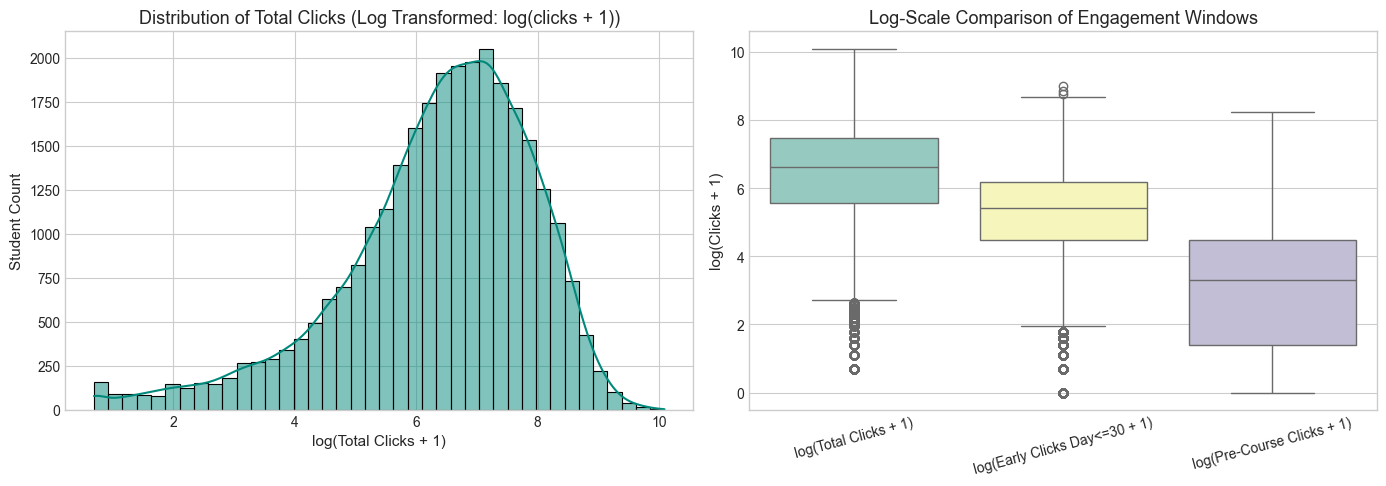

In [11]:
# Student-level VLE aggregations in an efficient single pass
vle_total = student_vle.groupby(['code_module', 'code_presentation', 'id_student'], observed=True).agg(
    total_clicks=('sum_click', 'sum'),
    active_days=('date', 'nunique')
).reset_index()

# Early engagement: Day <= 30
sv_early_30 = student_vle[student_vle['date'] <= 30]
vle_early_30 = sv_early_30.groupby(['code_module', 'code_presentation', 'id_student'], observed=True).agg(
    early_clicks_30=('sum_click', 'sum'),
    early_active_days_30=('date', 'nunique')
).reset_index()

# Pre-course engagement: Day < 0
sv_pre = student_vle[student_vle['date'] < 0]
vle_pre = sv_pre.groupby(['code_module', 'code_presentation', 'id_student'], observed=True).agg(
    pre_course_clicks=('sum_click', 'sum')
).reset_index()

# Merge VLE metric aggregations
vle_features = vle_total.merge(vle_early_30, on=['code_module', 'code_presentation', 'id_student'], how='left')
vle_features = vle_features.merge(vle_pre, on=['code_module', 'code_presentation', 'id_student'], how='left')
vle_num_cols = ['total_clicks', 'active_days', 'early_clicks_30', 'early_active_days_30', 'pre_course_clicks']
vle_features[vle_num_cols] = vle_features[vle_num_cols].fillna(0)

# Engagement percentiles and skewness
print("=== VLE Engagement Metrics Percentile Distribution ===")
percentiles = [0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
vle_stats = vle_features[['total_clicks', 'early_clicks_30', 'pre_course_clicks', 'active_days']].describe(percentiles=percentiles)
display(vle_stats.round(1))

# Visualizations: Skewness and Log distributions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Log-scale histogram of total clicks
sns.histplot(
    np.log1p(vle_features['total_clicks']),
    bins=40,
    kde=True,
    color='#00897b',
    ax=ax1
)
ax1.set_title('Distribution of Total Clicks (Log Transformed: log(clicks + 1))')
ax1.set_xlabel('log(Total Clicks + 1)')
ax1.set_ylabel('Student Count')

# Boxplot comparing engagement windows on log scale
log_eng_df = pd.DataFrame({
    'log(Total Clicks + 1)': np.log1p(vle_features['total_clicks']),
    'log(Early Clicks Day<=30 + 1)': np.log1p(vle_features['early_clicks_30']),
    'log(Pre-Course Clicks + 1)': np.log1p(vle_features['pre_course_clicks'])
})
sns.boxplot(data=log_eng_df, palette='Set3', ax=ax2)
ax2.set_title('Log-Scale Comparison of Engagement Windows')
ax2.set_ylabel('log(Clicks + 1)')
ax2.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

=== Zero-Click Student Rate Across Final Results (%) ===

=== Median and IQR of Engagement Across Final Results ===


,Zero VLE Clicks (%)
final_result,
Distinction,0.00
Fail,5.30
Pass,0.02
Withdrawn,29.42


,total_clicks,early_clicks_30,active_days
final_result,,,
Distinction,1896.0,413.5,103.0
Fail,317.0,136.5,22.0
Pass,1343.0,294.0,78.0
Withdrawn,89.0,60.0,7.0


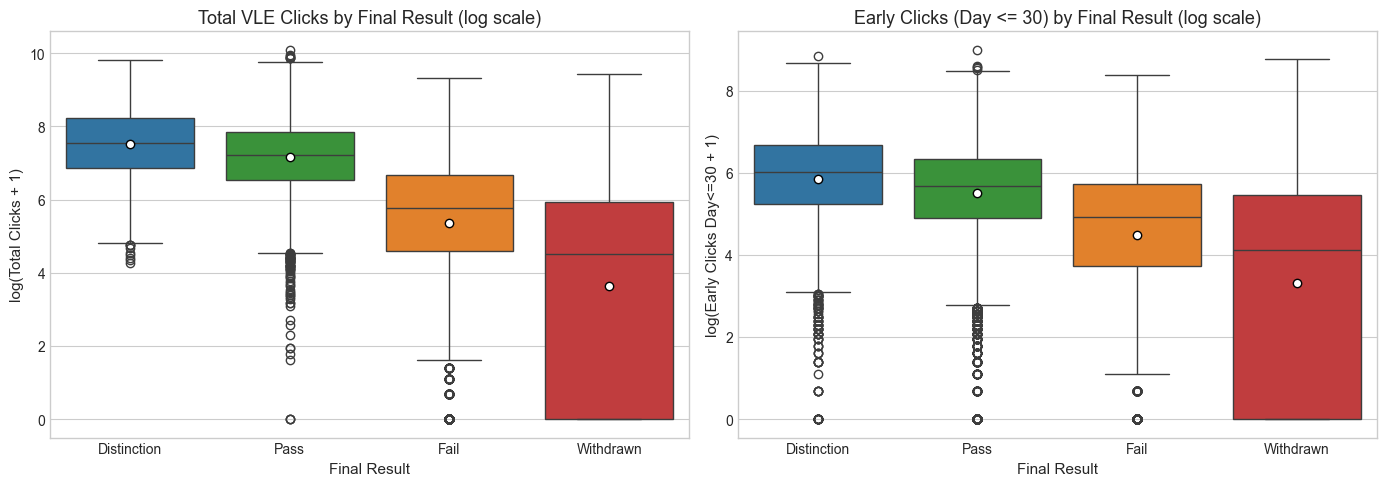

In [12]:
# Merge VLE metrics with student_info
df_vle_outcomes = student_info.merge(vle_features, on=['code_module', 'code_presentation', 'id_student'], how='left')

# Impute zero for students with no recorded VLE interactions
vle_fill_cols = ['total_clicks', 'active_days', 'early_clicks_30', 'early_active_days_30', 'pre_course_clicks']
df_vle_outcomes[vle_fill_cols] = df_vle_outcomes[vle_fill_cols].fillna(0)

# Check zero-engagement rates across final results
df_vle_outcomes['zero_clicks'] = df_vle_outcomes['total_clicks'] == 0
zero_click_rate = pd.crosstab(df_vle_outcomes['final_result'], df_vle_outcomes['zero_clicks'], normalize='index')[True] * 100

print("=== Zero-Click Student Rate Across Final Results (%) ===")
display(zero_click_rate.round(2).rename('Zero VLE Clicks (%)'))

print("\n=== Median and IQR of Engagement Across Final Results ===")
eng_summary = df_vle_outcomes.groupby('final_result')[['total_clicks', 'early_clicks_30', 'active_days']].median()
display(eng_summary)

# Visualizations: Engagement vs Final Result
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Total clicks by final_result (log scale)
sns.boxplot(
    data=df_vle_outcomes,
    x='final_result',
    y=np.log1p(df_vle_outcomes['total_clicks']),
    order=result_order,
    palette=palette_outcomes,
    ax=ax1,
    showmeans=True,
    meanprops={'marker': 'o', 'markerfacecolor': 'white', 'markeredgecolor': 'black'}
)
ax1.set_title('Total VLE Clicks by Final Result (log scale)')
ax1.set_xlabel('Final Result')
ax1.set_ylabel('log(Total Clicks + 1)')

# Early clicks (Day <= 30) by final_result (log scale)
sns.boxplot(
    data=df_vle_outcomes,
    x='final_result',
    y=np.log1p(df_vle_outcomes['early_clicks_30']),
    order=result_order,
    palette=palette_outcomes,
    ax=ax2,
    showmeans=True,
    meanprops={'marker': 'o', 'markerfacecolor': 'white', 'markeredgecolor': 'black'}
)
ax2.set_title('Early Clicks (Day <= 30) by Final Result (log scale)')
ax2.set_xlabel('Final Result')
ax2.set_ylabel('log(Early Clicks Day<=30 + 1)')

plt.tight_layout()
plt.show()

---

### Section 7: Correlation and Feature Relationships

In this section, we consolidate demographic, assessment, and engagement features at the student enrollment level to evaluate linear and rank correlations, feature associations, and potential predictors of academic risk.

=== Pearson Correlation with Academic Risk (is_at_risk) ===

=== Spearman Rank Correlation with Academic Risk (is_at_risk) ===


,Pearson r
active_days,-0.625964
assessments_submitted,-0.603816
total_clicks,-0.476574
mean_assessment_score,-0.432316
early_active_days_30,-0.394888
early_mean_score,-0.377416
early_clicks_30,-0.302346
pre_course_clicks,-0.208539
late_submissions,-0.136580
date_registration,-0.055986


,Spearman rho
active_days,-0.690180
total_clicks,-0.649217
assessments_submitted,-0.614381
early_active_days_30,-0.422235
mean_assessment_score,-0.415149
early_clicks_30,-0.410884
early_mean_score,-0.386936
pre_course_clicks,-0.316749
late_submissions,-0.071883
date_registration,-0.049283


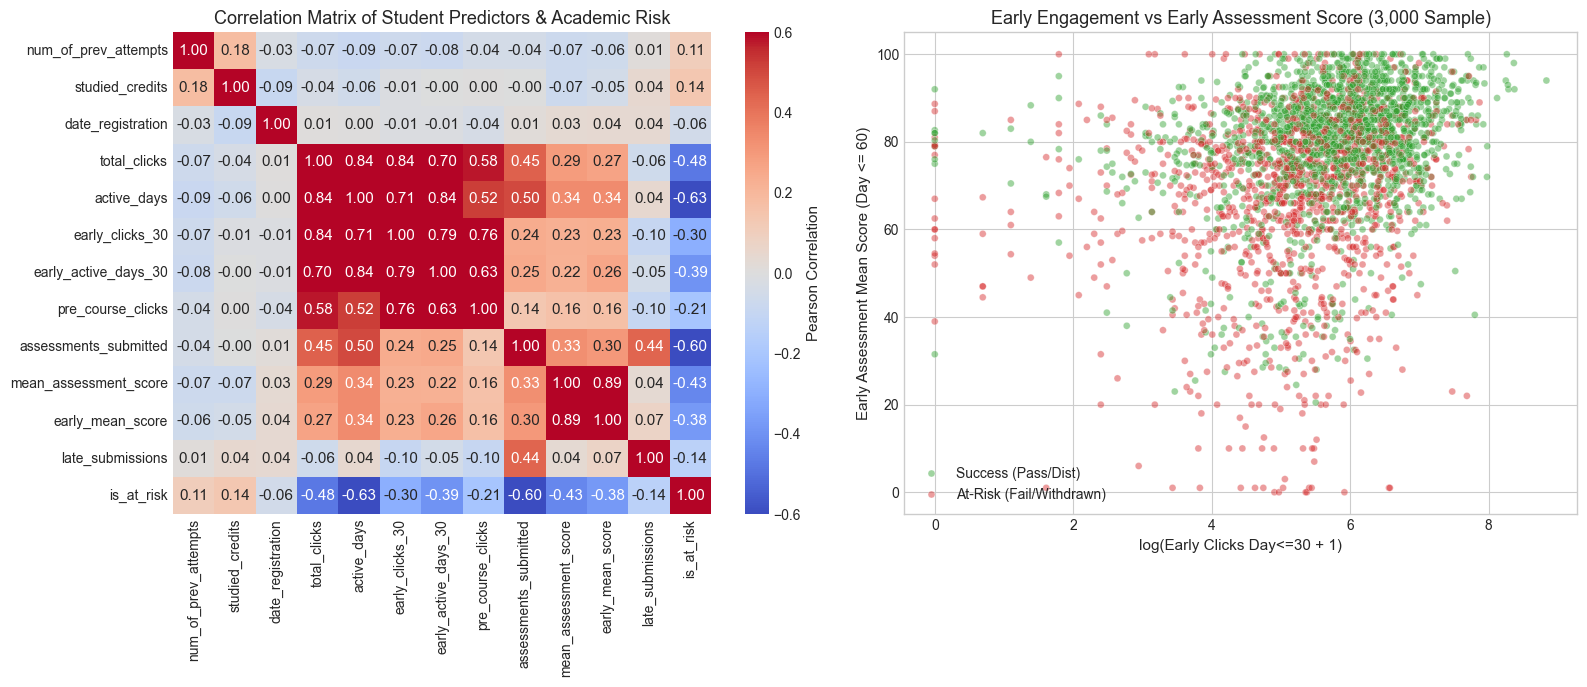

In [13]:
# Construct consolidated student-level analysis table
df_student_eda = student_info.merge(
    student_registration[['code_module', 'code_presentation', 'id_student', 'date_registration']],
    on=['code_module', 'code_presentation', 'id_student'],
    how='left'
)
df_student_eda = df_student_eda.merge(vle_features, on=['code_module', 'code_presentation', 'id_student'], how='left')
df_student_eda[vle_fill_cols] = df_student_eda[vle_fill_cols].fillna(0)
df_student_eda = df_student_eda.merge(asmt_student, on=['code_module', 'code_presentation', 'id_student'], how='left')
df_student_eda = df_student_eda.merge(asmt_early, on=['code_module', 'code_presentation', 'id_student'], how='left')

# Define binary risk label: 1 = At-Risk (Fail / Withdrawn), 0 = Success (Pass / Distinction)
df_student_eda['is_at_risk'] = df_student_eda['final_result'].isin(['Fail', 'Withdrawn']).astype(int)

# Select key numerical features for correlation analysis
analysis_features = [
    'num_of_prev_attempts',
    'studied_credits',
    'date_registration',
    'total_clicks',
    'active_days',
    'early_clicks_30',
    'early_active_days_30',
    'pre_course_clicks',
    'assessments_submitted',
    'mean_assessment_score',
    'early_mean_score',
    'late_submissions',
    'is_at_risk'
]

# Pearson and Spearman rank correlation matrices
pearson_corr = df_student_eda[analysis_features].corr(method='pearson')
spearman_corr = df_student_eda[analysis_features].corr(method='spearman')

print("=== Pearson Correlation with Academic Risk (is_at_risk) ===")
display(pearson_corr['is_at_risk'].sort_values().to_frame(name='Pearson r'))

print("\n=== Spearman Rank Correlation with Academic Risk (is_at_risk) ===")
display(spearman_corr['is_at_risk'].sort_values().to_frame(name='Spearman rho'))

# Visualizations: Heatmap and Bivariate Interaction
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7))

# Correlation Heatmap
sns.heatmap(
    pearson_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-0.6,
    vmax=0.6,
    ax=ax1,
    cbar_kws={'label': 'Pearson Correlation'}
)
ax1.set_title('Correlation Matrix of Student Predictors & Academic Risk')

# Scatter: Early Clicks vs Early Assessment Score colored by Risk Status (3000 sample)
sample_df = df_student_eda.dropna(subset=['early_mean_score']).sample(n=3000, random_state=42)
sns.scatterplot(
    data=sample_df,
    x=np.log1p(sample_df['early_clicks_30']),
    y='early_mean_score',
    hue='is_at_risk',
    palette={0: '#2ca02c', 1: '#d62728'},
    alpha=0.45,
    s=25,
    ax=ax2
)
ax2.set_title('Early Engagement vs Early Assessment Score (3,000 Sample)')
ax2.set_xlabel('log(Early Clicks Day<=30 + 1)')
ax2.set_ylabel('Early Assessment Mean Score (Day <= 60)')
handles, _ = ax2.get_legend_handles_labels()
ax2.legend(handles=handles, labels=['Success (Pass/Dist)', 'At-Risk (Fail/Withdrawn)'])

plt.tight_layout()
plt.show()

---

### Section 8: Summary of EDA Findings and Next Steps

In this section, we summarize key findings regarding feature utility, data quality issues, target leakage prevention, and guidelines for feature engineering in Notebook 03.

In [14]:
# Candidate feature audit and leakage prevention roadmap
feature_audit = [
    {
        "Feature Name": "early_clicks_30",
        "Data Source": "studentVle.csv",
        "Type": "Numerical (Discrete)",
        "Correlation with Risk": f"{pearson_corr.loc['early_clicks_30', 'is_at_risk']:.2f}",
        "Availability": "Pre-Cutoff (Day 30)",
        "Recommendation": "Strong Predictor; Log or Robust transformation required in Notebook 03."
    },
    {
        "Feature Name": "early_active_days_30",
        "Data Source": "studentVle.csv",
        "Type": "Numerical (Discrete)",
        "Correlation with Risk": f"{pearson_corr.loc['early_active_days_30', 'is_at_risk']:.2f}",
        "Availability": "Pre-Cutoff (Day 30)",
        "Recommendation": "Strong Predictor; Captures study consistency and active learning habits."
    },
    {
        "Feature Name": "early_mean_score",
        "Data Source": "studentAssessment.csv",
        "Type": "Numerical (Continuous)",
        "Correlation with Risk": f"{pearson_corr.loc['early_mean_score', 'is_at_risk']:.2f}",
        "Availability": "Early Semester (Day <= 60)",
        "Recommendation": "High Signal; Create binary missingness indicator for non-submissions."
    },
    {
        "Feature Name": "highest_education",
        "Data Source": "studentInfo.csv",
        "Type": "Categorical (Ordinal)",
        "Correlation with Risk": "Moderate Non-linear",
        "Availability": "Pre-Course (Enrolment)",
        "Recommendation": "Strong Demographic Signal; Ordinal encode in Notebook 03."
    },
    {
        "Feature Name": "imd_band",
        "Data Source": "studentInfo.csv",
        "Type": "Categorical (Ordinal)",
        "Correlation with Risk": "Monotonic Gradient",
        "Availability": "Pre-Course (Enrolment)",
        "Recommendation": "Socioeconomic Signal; Impute 1,111 missing values; Ordinal encode."
    },
    {
        "Feature Name": "num_of_prev_attempts",
        "Data Source": "studentInfo.csv",
        "Type": "Numerical (Discrete)",
        "Correlation with Risk": f"+{pearson_corr.loc['num_of_prev_attempts', 'is_at_risk']:.2f}",
        "Availability": "Pre-Course (Enrolment)",
        "Recommendation": "Direct risk signal; Higher attempts strongly associate with course failure."
    },
    {
        "Feature Name": "studied_credits",
        "Data Source": "studentInfo.csv",
        "Type": "Numerical (Discrete)",
        "Correlation with Risk": f"+{pearson_corr.loc['studied_credits', 'is_at_risk']:.2f}",
        "Availability": "Pre-Course (Enrolment)",
        "Recommendation": "Useful Signal; Workload overburden indicator (credits > 120)."
    },
    {
        "Feature Name": "date_unregistration",
        "Data Source": "studentRegistration.csv",
        "Type": "Numerical / Date",
        "Correlation with Risk": "N/A (Target Leakage)",
        "Availability": "Post-Event Only",
        "Recommendation": "EXCLUDE: 100% target leakage for Withdrawn students."
    },
    {
        "Feature Name": "total_clicks (Full Course)",
        "Data Source": "studentVle.csv",
        "Type": "Numerical (Discrete)",
        "Correlation with Risk": f"{pearson_corr.loc['total_clicks', 'is_at_risk']:.2f}",
        "Availability": "End of Course Only",
        "Recommendation": "EXCLUDE from early prediction models; Causes temporal leakage."
    },
    {
        "Feature Name": "id_student",
        "Data Source": "All Tables",
        "Type": "Identifier",
        "Correlation with Risk": "None",
        "Availability": "Identifier",
        "Recommendation": "EXCLUDE: Arbitrary key with no generalizable relationship."
    }
]

feature_audit_df = pd.DataFrame(feature_audit)
print("=== Candidate Feature Summary & Leakage Prevention Roadmap ===")
display(feature_audit_df)

=== Candidate Feature Summary & Leakage Prevention Roadmap ===


,Feature Name,Data Source,Type,Correlation with Risk,Availability,Recommendation
0,early_clicks_30,studentVle.csv,Numerical (Discrete),-0.30,Pre-Cutoff (Day 30),Strong Predictor; Log or Robust transformation required in Notebook 03.
1,early_active_days_30,studentVle.csv,Numerical (Discrete),-0.39,Pre-Cutoff (Day 30),Strong Predictor; Captures study consistency and active learning habits.
2,early_mean_score,studentAssessment.csv,Numerical (Continuous),-0.38,Early Semester (Day <= 60),High Signal; Create binary missingness indicator for non-submissions.
3,highest_education,studentInfo.csv,Categorical (Ordinal),Moderate Non-linear,Pre-Course (Enrolment),Strong Demographic Signal; Ordinal encode in Notebook 03.
4,imd_band,studentInfo.csv,Categorical (Ordinal),Monotonic Gradient,Pre-Course (Enrolment),"Socioeconomic Signal; Impute 1,111 missing values; Ordinal encode."
5,num_of_prev_attempts,studentInfo.csv,Numerical (Discrete),+0.11,Pre-Course (Enrolment),Direct risk signal; Higher attempts strongly associate with course failure.
6,studied_credits,studentInfo.csv,Numerical (Discrete),+0.14,Pre-Course (Enrolment),Useful Signal; Workload overburden indicator (credits > 120).
7,date_unregistration,studentRegistration.csv,Numerical / Date,N/A (Target Leakage),Post-Event Only,EXCLUDE: 100% target leakage for Withdrawn students.
8,total_clicks (Full Course),studentVle.csv,Numerical (Discrete),-0.48,End of Course Only,EXCLUDE from early prediction models; Causes temporal leakage.
9,id_student,All Tables,Identifier,None,Identifier,EXCLUDE: Arbitrary key with no generalizable relationship.
